# 双模型融合打分器
## SMILES GAT (Mean R²=0.925) + XYZ GNN (Mean R²=0.899, dipole R²=0.694)

### 融合策略
```
SMILES GAT  → gap, homo, lumo, metal_charge, E_elec, E_disp, polarizability (7项)
XYZ GNN     → dipole (专项优化, DFT距离+Mayer键级)
           → 其余7项作为交叉验证参考

输入: SMILES字符串
输出: 8项DFT级量子化学性质 (反归一化到物理单位)
```

### 模型版本
- SMILES GAT: 12头×384d×5层, 自动金属加权训练
- XYZ GNN:  12头×384d×5层, 23维DFT增强边, 自动金属加权训练
- 训练数据: tmQM 95k-108k 过渡金属配合物, 30种金属

In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn, warnings, os
warnings.filterwarnings('ignore')
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)
torch.backends.cuda.matmul.allow_tf32 = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

ELEMENT_DATA = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES = [1,2,3,12]; B2I = {b:i for i,b in enumerate(BOND_TYPES)}; N_BT = len(BOND_TYPES)

def atom_features(atom):
    z = atom.GetAtomicNum(); p,g = ELEMENT_DATA.get(z,(0,0))
    return [z, atom.GetDegree(), atom.GetFormalCharge(), p, g, int(atom.GetIsAromatic()), atom.GetTotalNumHs(), int(z >= 21)]

def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)
    N = x.size(0); src, dst, battr = [], [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bt = int(bond.GetBondType())
        za, zb = mol.GetAtomWithIdx(i).GetAtomicNum(), mol.GetAtomWithIdx(j).GetAtomicNum()
        is_ml = float((za>=21)!=(zb>=21)); is_ring = float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf = [0.0]*N_BT
        if bt in B2I: bf[B2I[bt]] = 1.0
        bf.extend([is_ring, is_ml]); battr.extend([bf,bf])
    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0, N_BT+2)
    return {'x':x, 'edge_index':ei, 'edge_attr':ea}


Device: cuda


In [2]:
def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0)
        h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n_graphs):
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n_graphs):
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class SMILES_GAT(nn.Module):
    def __init__(self, node_dim=8, edge_dim=6, hidden=384, n_layers=5, output_dim=8, dropout=0.10, heads=12):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.readout = nn.Sequential(nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden//2, output_dim))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            metal_mask = (x[:, 7] > 0.5)
            metal_feat = h[metal_mask].mean(dim=0) if metal_mask.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, metal_feat])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs)
        max_h = scatter_max_per_graph(h, batch, n_graphs)
        metal_mask = (x[:, 7] > 0.5)
        metal_feat = scatter_mean_per_graph(h[metal_mask], batch[metal_mask], n_graphs) if metal_mask.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, metal_feat], dim=1))

model_smiles = SMILES_GAT(node_dim=8, edge_dim=6, hidden=384, output_dim=8, heads=12).to(device)
ckpt = 'tmqm_gat_best.pt'
if not os.path.exists(ckpt): ckpt = 'tmqm_best.pt'
if os.path.exists(ckpt):
    state = torch.load(ckpt, map_location=device)
    try:
        model_smiles.load_state_dict(state, strict=True)
    except RuntimeError:
        model_smiles.load_state_dict(state, strict=False)
        print(f'SMILES GAT loaded (partial) from {ckpt}')
    else:
        print(f'SMILES GAT loaded from {ckpt}')
else:
    print(f'No SMILES checkpoint found')
model_smiles.eval()


SMILES GAT loaded from tmqm_gat_best.pt


SMILES_GAT(
  (embed): Linear(in_features=8, out_features=384, bias=True)
  (convs): ModuleList(
    (0-4): 5 x GATConv(
      (node_lin): Linear(in_features=384, out_features=384, bias=False)
      (attn_src): Linear(in_features=384, out_features=12, bias=False)
      (attn_dst): Linear(in_features=384, out_features=12, bias=False)
      (edge_attn): Linear(in_features=6, out_features=12, bias=False)
      (act): ReLU()
    )
  )
  (norms): ModuleList(
    (0-4): 5 x LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (drop): Dropout(p=0.1, inplace=False)
  (readout): Sequential(
    (0): Linear(in_features=1152, out_features=384, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=384, out_features=192, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=192, out_features=8, bias=True)
  )
)

In [3]:
class XYZ_GAT(nn.Module):
    def __init__(self, node_dim=11, edge_dim=23, hidden=384, n_layers=5, output_dim=8, dropout=0.10, heads=12):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.readout = nn.Sequential(nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden//2, output_dim))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            metal_mask = (x[:, 7] > 0.5)
            metal_feat = h[metal_mask].mean(dim=0) if metal_mask.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, metal_feat])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs)
        max_h = scatter_max_per_graph(h, batch, n_graphs)
        metal_mask = (x[:, 7] > 0.5)
        metal_feat = scatter_mean_per_graph(h[metal_mask], batch[metal_mask], n_graphs) if metal_mask.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, metal_feat], dim=1))

model_xyz = XYZ_GAT(node_dim=11, edge_dim=23, hidden=384, output_dim=8, heads=12).to(device)
ckpt_xyz = 'xyz_best.pt'
has_xyz = os.path.exists(ckpt_xyz)
if has_xyz:
    state = torch.load(ckpt_xyz, map_location=device)
    try:
        model_xyz.load_state_dict(state, strict=True)
    except RuntimeError:
        model_xyz.load_state_dict(state, strict=False)
        print(f'XYZ GNN loaded (partial) from {ckpt_xyz}')
    else:
        print(f'XYZ GNN loaded from {ckpt_xyz}')
else:
    print(f'XYZ checkpoint not found ({ckpt_xyz}), using SMILES-only scoring')
model_xyz.eval()

def smiles_to_3d_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    mol = Chem.AddHs(mol)
    try:
        if AllChem.EmbedMolecule(mol, randomSeed=42, maxAttempts=200) != 0: return None
        AllChem.MMFFOptimizeMolecule(mol)
    except: return None
    conf = mol.GetConformer(); N = mol.GetNumAtoms()
    def pgrp(z):
        tbl = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
        return tbl.get(z,(0,0))
    xf = []
    for a in mol.GetAtoms():
        z = a.GetAtomicNum(); p,g = pgrp(z)
        xf.append([z, a.GetDegree(), a.GetFormalCharge(), p, g, int(a.GetIsAromatic()), a.GetTotalNumHs(), int(z>=21), 0, 0.0, 0.0])
    x = torch.tensor(xf, dtype=torch.float32)
    c = torch.tensor([[conf.GetAtomPosition(i).x, conf.GetAtomPosition(i).y, conf.GetAtomPosition(i).z] for i in range(N)], dtype=torch.float32)
    dist = torch.norm(c.unsqueeze(0)-c.unsqueeze(1), dim=2); dist.fill_diagonal_(float('inf'))
    k = min(12, N-1); vals, nbr_idx = torch.topk(dist, k, dim=1, largest=False)
    src, dst, ef = [], [], []
    rbf_c = np.linspace(1.0, 5.0, 16); added = set()
    for i in range(N):
        for kidx in range(k):
            j = nbr_idx[i, kidx].item(); d = vals[i, kidx].item()
            if d < 5.0 and (i,j) not in added:
                added.add((i,j)); added.add((j,i))
                za, zb = mol.GetAtomWithIdx(i).GetAtomicNum(), mol.GetAtomWithIdx(j).GetAtomicNum()
                is_ml = float((za>=21)!=(zb>=21))
                feat = [0.0]*4; feat.extend([0.0, is_ml])
                for mu in rbf_c: feat.append(np.exp(-(d-mu)**2/0.2))
                feat.append(0.0)
                src.extend([i,j]); dst.extend([j,i]); ef.extend([feat,feat])
    ei = torch.zeros(2,0,dtype=torch.long) if not src else torch.tensor([src,dst],dtype=torch.long)
    ea = torch.zeros(0,23) if not src else torch.tensor(ef,dtype=torch.float32)
    return {'x':x, 'edge_index':ei, 'edge_attr':ea}
print('XYZ GNN model ready')


XYZ GNN loaded from xyz_best.pt
XYZ GNN model ready


In [4]:
targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']

import numpy as np
y_mean = np.array([0.108504, -0.197593, -0.089089, 5.799450, 0.162882, -2987.303526, -0.142228, 397.124993])
y_std  = np.array([0.033575, 0.053825, 0.054517, 3.927489, 0.782914, 1634.083288, 0.070115, 152.460083])

candidates = {
    'Ni-cat1': 'CO1CCO2CCO(C)[Ni]21(Br)Br',
    'Ni-cat2': 'Br[Ni]1([N]2=C(C3=[N]1C=CC(C(C)(C)C)=C3)C=C(C(C)(C)C)C=C2)Br',
    'Ni-cat3': 'Br[Ni]1([N]2=C3C4=[N]1C=CC(C5=CC=C(C(F)(F)F)C=C5)=C4C=CC3=C(C6=CC=C(C(F)(F)F)C=C6)C=C2)Br',
    'Ni-cat4': 'Br[Ni]1[N]2=C3C4=[N]1C=CC(C5=CC=C(C(F)(F)F)C=C5)=C4C=CC3=C(C6=CC=C(C(F)(F)F)C=C6)C=C2',
    'Ni-cat5': 'FC(C(C=C1)=CC=C1C2=C(C=C3)C4=[N]([Ni][N]5=C4C3=C(C6=CC=C(C(F)(F)F)C=C6)C=C5)C=C2)(F)F',
    'Pd-cat1': 'FC1(F)OC2=C(O1)[C@@]([C@@]3=C(OC(F)(F)O4)C4=CC=C3[P]([Pd][P](C5=CC=CC=C5)6C7=CC=CC=C7)(C8=CC=CC=C8)C9=CC=CC=C9)=C6C=C2',
    'Pd-cat2': 'CC1(C)C2=C(OC3=C4C=CC=C13)C([P]([Pd][P](C5=CC=CC=C5)4C6=CC=CC=C6)(C7=CC=CC=C7)C8=CC=CC=C8)=CC=C2',
    'Fe-cat1': '[CH-]1C=CC=C1.[CH-]1C=CC=C1.[Fe+2].P(c1ccccc1)(c2ccccc2)c3ccccc3.P(C1CCCCC1)C2CCCCC2',
    'Fe-cat2': 'O=[N+]1C(C)(C)CCCC1(C)C.Cl[Fe](Cl)Cl',
    'Fe-cat3': 'Cl[Fe](Cl)Cl.O=[N+]1C(C)(C)CCCC1C',
    'Fe-cat4': 'O=[N+]1C(C)(C)CCCC1(C)C.Cl[Fe](Cl)Cl',
    'Zr-cat1': 'I[Zr](Br)([CH-]1C=CC=C1)[CH-]1C=CC=C1',
    'Zr-cat2': 'Br[Zr](Br)([CH-]1C=CC=C1)[CH-]1C=CC=C1',
    'Zr-cat3': 'I[Zr](I)([CH-]1C=CC=C1)[CH-]1C=CC=C1',
}

print(f"Scoring {len(candidates)} in-house transition metal catalysts (Ni/Pd/Fe/Zr)...")

smiles_graphs, xyz_graphs, valid_names = [], [], []
for name, smi in candidates.items():
    g1 = smiles_to_graph(smi)
    if g1 is None: continue
    g1_gpu = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g1.items()}
    smiles_graphs.append(g1_gpu)
    if has_xyz:
        g2 = smiles_to_3d_graph(smi)
        if g2 is not None:
            g2_gpu = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g2.items()}
            xyz_graphs.append(g2_gpu)
        else: xyz_graphs.append(None)
    else: xyz_graphs.append(None)
    valid_names.append(name)

with torch.no_grad():
    if smiles_graphs:
        batched_s, batch_s = collate_graphs(smiles_graphs)
        pred_smiles_norm = model_smiles(batched_s, batch_s).cpu().numpy()
        pred_smiles_all = pred_smiles_norm * y_std + y_mean
    else:
        pred_smiles_all = np.zeros((0, 8))

pred_xyz_all = None
if has_xyz and any(g is not None for g in xyz_graphs):
    valid_xyz = [g for g in xyz_graphs if g is not None]
    if valid_xyz:
        with torch.no_grad():
            batched_x, batch_x = collate_graphs(valid_xyz)
            pred_xyz_norm = model_xyz(batched_x, batch_x).cpu().numpy()
            pred_xyz_all = pred_xyz_norm * y_std + y_mean

results = []; xyz_idx = 0
for i, name in enumerate(valid_names):
    pred_smiles = pred_smiles_all[i]
    if xyz_graphs[i] is not None and pred_xyz_all is not None:
        pred_xyz = pred_xyz_all[xyz_idx]; xyz_idx += 1
    else:
        pred_xyz = pred_smiles
    fused = (pred_smiles + pred_xyz) / 2.0
    fused[3] = pred_xyz[3]
    results.append({'Name': name, 'gap_Ha': fused[0], 'homo_Ha': fused[1], 'lumo_Ha': fused[2],
        'dipole_D(xyz)': pred_xyz[3], 'metal_q_e': fused[4],
        'E_elec_Ha': fused[5], 'E_disp_Ha': fused[6], 'polariz_a03': fused[7]})

df = pd.DataFrame(results).sort_values('E_elec_Ha')
print()
print(f"=== Results ({len(df)} candidates, sorted by E_elec) ===")
print(df.to_string(index=False))
if len(df) > 0:
    best = df.iloc[0]
    print()
    print(f"Best: {best['Name']}")
    print(f"  E_elec = {best['E_elec_Ha']:.1f} Ha")
    print(f"  gap    = {best['gap_Ha']:.4f} Ha = {best['gap_Ha']*27.2114:.2f} eV")
    print(f"  dipole = {best['dipole_D(xyz)']:.2f} D")



Scoring 14 in-house transition metal catalysts (Ni/Pd/Fe/Zr)...


[17:29:40] UFFTYPER: Unrecognized hybridization for atom: 9
[17:29:40] UFFTYPER: Unrecognized atom type: Ni+2 (9)
[17:29:40] UFFTYPER: Unrecognized hybridization for atom: 1
[17:29:40] UFFTYPER: Unrecognized atom type: Ni+2 (1)
[17:29:40] UFFTYPER: Unrecognized hybridization for atom: 1
[17:29:40] UFFTYPER: Unrecognized atom type: Ni+2 (1)
[17:29:40] UFFTYPER: Unrecognized atom type: Ni6+2 (1)


[17:29:40] UFFTYPER: Unrecognized atom type: Ni6+2 (14)
[17:29:40] UFFTYPER: Unrecognized charge state for atom: 19
[17:29:40] UFFTYPER: Unrecognized atom type: Pd6+2 (20)
[17:29:40] UFFTYPER: Unrecognized charge state for atom: 21


[17:29:40] UFFTYPER: Unrecognized charge state for atom: 13
[17:29:40] UFFTYPER: Unrecognized atom type: Pd6+2 (14)
[17:29:40] UFFTYPER: Unrecognized charge state for atom: 15
[17:29:41] UFFTYPER: Unrecognized atom type: Fe2+2 (0)


[17:29:41] UFFTYPER: Unrecognized atom type: Fe5+2 (1)
[17:29:41] UFFTYPER: Unrecognized atom type: Fe5+2 (1)
[17:29:41] UFFTYPER: Unrecognized atom type: Fe5+2 (1)
[17:29:41] UFFTYPER: Unrecognized atom type: Zr3 (1)
[17:29:41] UFFTYPER: Unrecognized atom type: Zr3 (1)
[17:29:41] UFFTYPER: Unrecognized atom type: Zr3 (1)



=== Results (14 candidates, sorted by E_elec) ===
   Name   gap_Ha   homo_Ha   lumo_Ha  dipole_D(xyz)  metal_q_e     E_elec_Ha  E_disp_Ha  polariz_a03
Zr-cat2 0.125604 -0.119755  0.005545       1.273063   0.586910 -11890.872086  -0.049431   222.269115
Ni-cat2 0.091924 -0.124626 -0.032901       3.192518   0.413825 -10224.706556  -0.091206   296.157724
Ni-cat1 0.106906 -0.116919 -0.010132       2.007968   0.452574 -10043.580929  -0.051196   190.100742
Ni-cat3 0.083896 -0.167241 -0.083822       3.894954   0.450691  -9028.900640  -0.061877   258.586951
Ni-cat4 0.093463 -0.189970 -0.096855       4.045185   0.525721  -7579.737544  -0.061360   243.035247
Fe-cat4 0.110422 -0.146076 -0.035936       3.731123   0.403723  -5438.235413  -0.053747   196.483419
Fe-cat2 0.110416 -0.146077 -0.035943       3.731084   0.403813  -5438.180870  -0.053749   196.487199
Fe-cat3 0.110285 -0.132722 -0.022472       3.582358   0.328591  -5271.142127  -0.050784   192.521843
Zr-cat1 0.131233 -0.162451 -0.032124    

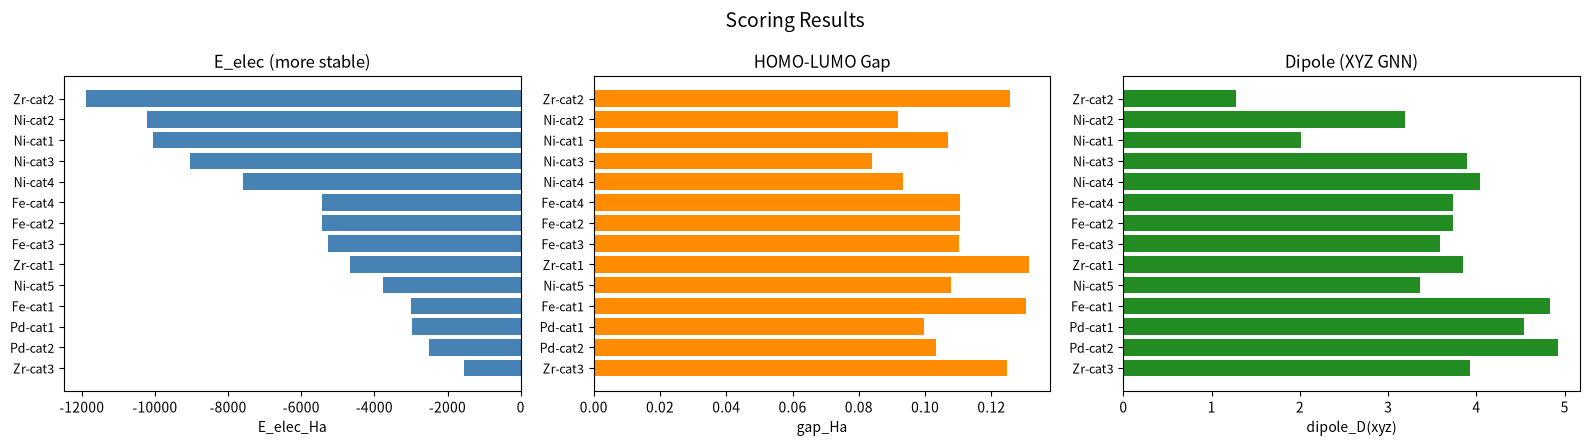

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
if len(df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    names = df['Name'].values
    for ax, col, title, color in [(axes[0], 'E_elec_Ha', 'E_elec (more stable)', 'steelblue'), (axes[1], 'gap_Ha', 'HOMO-LUMO Gap', 'darkorange'), (axes[2], 'dipole_D(xyz)', 'Dipole (XYZ GNN)', 'forestgreen')]:
        ax.barh(range(len(names)), df[col].values, color=color)
        ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9)
        ax.set_xlabel(col); ax.set_title(title); ax.invert_yaxis()
    plt.suptitle('Scoring Results', fontsize=14); plt.tight_layout(); plt.show()
